In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1) Aprendizado supervisionado - Regressão


In [37]:
regressao_data = pd.read_csv('/Users/izadoraganem/7º período/TP2_IIA/Dados TP2/regressao.csv')
regressao_data

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,target
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,no,no,4,3,4,1,1,3,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,yes,no,5,3,3,1,1,3,4,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,yes,no,4,3,2,2,3,3,10,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,yes,yes,3,2,2,1,1,5,2,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,no,no,4,3,2,1,2,5,4,10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
390,MS,M,20,U,LE3,A,2,2,services,services,...,no,no,5,5,4,4,5,4,11,9
391,MS,M,17,U,LE3,T,3,1,services,services,...,yes,no,2,4,5,3,4,2,3,16
392,MS,M,21,R,GT3,T,1,1,other,other,...,no,no,5,5,3,3,3,3,3,7
393,MS,M,18,R,LE3,T,3,2,services,other,...,yes,no,4,4,1,3,4,5,0,10


In [77]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from scipy.stats import zscore

X = regressao_data.drop('target', axis=1)
y = regressao_data['target']

for col in X.select_dtypes(include='object').columns:
    encoding = LabelEncoder()
    X[col] = encoding.fit_transform(X[col])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=27)


## 1.



### a) Regressão Linear

In [71]:
regressao_linear = LinearRegression()
regressao_linear.fit(X_train, y_train)
y_pred_regressao_linear = regressao_linear.predict(X_test)
rmse_regressao_linear = np.sqrt(mean_squared_error(y_test, y_pred_regressao_linear))

print(f"RMSE regressão linear: {round(rmse_regressao_linear, 2)}")

RMSE regressão linear: 4.43


### b) Random Forest

In [72]:
random_forest = RandomForestRegressor(random_state=42)
random_forest.fit(X_train, y_train)
y_pred_random_forest = random_forest.predict(X_test)
rmse_random_forest = np.sqrt(mean_squared_error(y_test, y_pred_random_forest))

print(f"RMSE random rorest: {round(rmse_random_forest, 2)}")


RMSE random rorest: 3.88


### c) Support Vector Regression (SVR)

In [73]:
svr = SVR()
svr.fit(X_train, y_train)  
y_pred_svr = svr.predict(X_test)
rmse_svr = np.sqrt(mean_squared_error(y_test, y_pred_svr))

print(f"RMSE SVR: {round(rmse_svr, 2)}")


RMSE SVR: 4.66


### d) Modelo regressivo escolhido: Extra Tree Regressor

In [42]:
extraTree = ExtraTreesRegressor(random_state=7)
extraTree.fit(X_train, y_train)
y_pred_extraTree = extraTree.predict(X_test)
rmse_extraTree = np.sqrt(mean_squared_error(y_test, y_pred_extraTree))

print(f"RMSE Extra Tree: {round(rmse_extraTree, 2)}")


RMSE Extra Tree: 4.36


## 2.

In [ ]:
features_regressao_linear = pd.Series(regressao_linear.coef_, index=X.columns).sort_values(key=abs, ascending=False)
print("Importância das features regressão linear:")
print(features_regressao_linear)

Importância das features regressão linear:
failures     -1.721166
higher        1.700639
sex           1.300738
famsup       -1.204766
romantic     -0.952486
Pstatus      -0.803206
internet      0.792493
paid          0.792409
schoolsup    -0.713398
studytime     0.707560
famsize       0.701210
activities   -0.694812
school        0.609279
Medu          0.529818
goout        -0.403895
nursery      -0.342199
age          -0.331318
address       0.329897
freetime      0.294835
famrel        0.247065
reason        0.238589
guardian      0.233552
traveltime   -0.233475
Mjob         -0.170237
Dalc         -0.164750
Fjob          0.075690
health       -0.069305
Fedu         -0.067077
absences      0.057863
Walc         -0.006289
dtype: float64


In [44]:
features_random_forest = pd.Series(random_forest.feature_importances_, index=X.columns).sort_values(ascending=False)
print("Importância das features random forest:")
print(features_random_forest)

Importância das features random forest:
absences      0.173240
failures      0.103987
age           0.060490
goout         0.044464
Mjob          0.042784
studytime     0.041614
freetime      0.041516
health        0.040220
Fjob          0.035789
Medu          0.034670
Walc          0.032101
Fedu          0.031640
famrel        0.028970
schoolsup     0.028854
reason        0.028668
traveltime    0.026541
guardian      0.023737
sex           0.022272
romantic      0.020710
activities    0.020707
higher        0.017146
famsup        0.015681
school        0.014853
famsize       0.012135
paid          0.011537
Pstatus       0.010849
Dalc          0.009695
nursery       0.009636
internet      0.008607
address       0.006886
dtype: float64


## 3.

In [53]:
top15features = features_regressao_linear[:15].index

X_top15 = X[top15features]
X_train_top15, X_test_top15, y_train_top15, y_test_top15 = train_test_split(X_top15, y, test_size=0.2, random_state=27)
regressao_linear.fit(X_train_top15, y_train_top15)
rmse_regressao_linear = np.sqrt(mean_squared_error(y_test_top15, regressao_linear.predict(X_test_top15)))

print(f"RMSE regressão linear top 15 features: {round(rmse_regressao_linear, 2)}")

RMSE regressão linear top 15 features: 4.24


In [56]:
top15features = features_random_forest[:15].index

X_top15 = X[top15features]
X_train_top15, X_test_top15, y_train_top15, y_test_top15 = train_test_split(X_top15, y, test_size=0.2, random_state=27)
random_forest.fit(X_train_top15, y_train_top15)
rmse_random_forest = np.sqrt(mean_squared_error(y_test_top15, random_forest.predict(X_test_top15)))

print(f"RMSE random forest top 15 features: {round(rmse_random_forest, 2)}")

RMSE random forest top 15 features: 3.98


## 4.

#### Standard Scaler

In [67]:
scaler_std = StandardScaler()
X_train_std = scaler_std.fit_transform(X_train)
X_test_std = scaler_std.transform(X_test)

regressao_linear.fit(X_train_std, y_train)
y_pred_regressao_linear = regressao_linear.predict(X_test_std)
rmse_regressao_linear = np.sqrt(mean_squared_error(y_test, y_pred_regressao_linear))


random_forest.fit(X_train_std, y_train)
y_pred_random_forest = random_forest.predict(X_test_std)
rmse_random_forest = np.sqrt(mean_squared_error(y_test, y_pred_random_forest))


svr.fit(X_train_std, y_train)  
y_pred_svr = svr.predict(X_test_std)
rmse_svr = np.sqrt(mean_squared_error(y_test, y_pred_svr))

print(f"RMSE regressão linear com StandardScaler: {round(rmse_regressao_linear, 2)}")
print(f"RMSE random forest com StandardScaler: {round(rmse_random_forest, 2)}")
print(f"RMSE SVR com StandardScaler: {round(rmse_svr, 2)}")

RMSE regressão linear com StandardScaler: 4.43
RMSE random forest com StandardScaler: 3.9
RMSE SVR com StandardScaler: 4.46


#### Min Max Scaler

In [68]:
scaler_mm = MinMaxScaler()
X_train_mm = scaler_mm.fit_transform(X_train)
X_test_mm = scaler_mm.transform(X_test)

regressao_linear.fit(X_train_mm, y_train)
y_pred_regressao_linear = regressao_linear.predict(X_test_mm)
rmse_regressao_linear = np.sqrt(mean_squared_error(y_test, y_pred_regressao_linear))

random_forest.fit(X_train_mm, y_train)
y_pred_random_forest = random_forest.predict(X_test_mm)
rmse_random_forest = np.sqrt(mean_squared_error(y_test, y_pred_random_forest))

svr.fit(X_train_mm, y_train)
y_pred_svr = svr.predict(X_test_mm)
rmse_svr = np.sqrt(mean_squared_error(y_test, y_pred_svr))

print(f"RMSE regressão linear com MinMaxScaler: {round(rmse_regressao_linear, 2)}")
print(f"RMSE random forest com MinMaxScaler: {round(rmse_random_forest, 2)}")
print(f"RMSE SVR com MinMaxScaler: {round(rmse_svr, 2)}")

RMSE regressão linear com MinMaxScaler: 4.43
RMSE random forest com MinMaxScaler: 3.89
RMSE SVR com MinMaxScaler: 4.54


## 5.

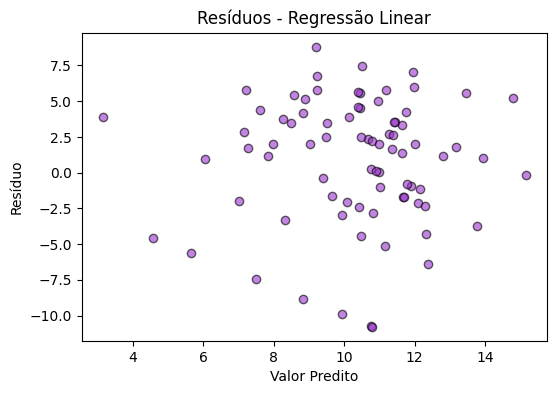

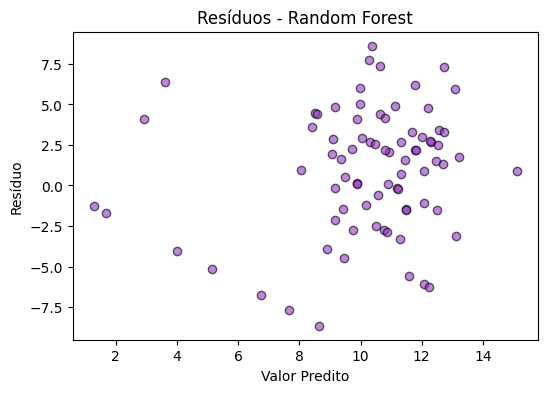

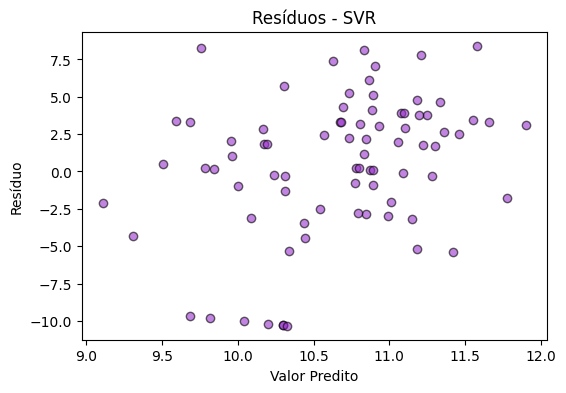

In [65]:
def plot_residuos(y_true, y_pred, title):
    residuos = y_true - y_pred
    plt.figure(figsize=(6,4))
    plt.scatter(y_pred, residuos, alpha=0.6, color='darkorchid', edgecolors='black')
    plt.xlabel("Valor Predito")
    plt.ylabel("Resíduo")
    plt.title(f"Resíduos - {title}")
    plt.show()

plot_residuos(y_test, y_pred_regressao_linear, "Regressão Linear")
plot_residuos(y_test, y_pred_random_forest, "Random Forest")
plot_residuos(y_test, y_pred_svr, "SVR")


## 6.

#### Z-score

In [79]:
z_scores = np.abs(zscore(X))

filtro_z = (z_scores < 3).all(axis=1)

X_clean = X[filtro_z]
y_clean = y[filtro_z]

print(f"Registros antes: {len(X)}")
print(f"Registros após remoção de outliers (Z-score): {len(X_clean)}")


Registros antes: 395
Registros após remoção de outliers (Z-score): 342


In [80]:
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X_clean, y_clean, test_size=0.2, random_state=42)

regressao_linear.fit(X_train_c, y_train_c)
y_pred_regressao_linear_c = regressao_linear.predict(X_test_c)
rmse_regressao_linear_c = np.sqrt(mean_squared_error(y_test_c, y_pred_regressao_linear_c))


random_forest.fit(X_train_c, y_train_c)
y_pred_random_forest_c = random_forest.predict(X_test_c)
rmse_random_forest_c = np.sqrt(mean_squared_error(y_test_c, y_pred_random_forest_c))

svr.fit(X_train_c, y_train_c)
y_pred_svr_c = svr.predict(X_test_c)
rmse_svr_c = np.sqrt(mean_squared_error(y_test_c, y_pred_svr_c))

print(f"RMSE regressão linear após remoção de outliers: {round(rmse_regressao_linear_c, 2)}")
print(f"RMSE random forest após remoção de outliers: {round(rmse_random_forest_c, 2)}")
print(f"RMSE SVR após remoção de outliers: {round(rmse_svr_c, 2)}")

RMSE regressão linear após remoção de outliers: 4.75
RMSE random forest após remoção de outliers: 4.43
RMSE SVR após remoção de outliers: 4.48


# 2 - Aprendizado supervisionado - Classificação

In [83]:
classificacao_data = pd.read_csv('/Users/izadoraganem/7º período/TP2_IIA/Dados TP2/classificacao.csv')
classificacao_data

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,target
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,no,no,4,3,4,1,1,3,6,F
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,yes,no,5,3,3,1,1,3,4,F
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,yes,no,4,3,2,2,3,3,10,D
3,GP,F,15,U,GT3,T,4,2,health,services,...,yes,yes,3,2,2,1,1,5,2,B
4,GP,F,16,U,GT3,T,3,3,other,other,...,no,no,4,3,2,1,2,5,4,D
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
390,MS,M,20,U,LE3,A,2,2,services,services,...,no,no,5,5,4,4,5,4,11,F
391,MS,M,17,U,LE3,T,3,1,services,services,...,yes,no,2,4,5,3,4,2,3,A
392,MS,M,21,R,GT3,T,1,1,other,other,...,no,no,5,5,3,3,3,3,3,F
393,MS,M,18,R,LE3,T,3,2,services,other,...,yes,no,4,4,1,3,4,5,0,D


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.metrics import f1_score
from sklearn.metrics import classification_report,
import seaborn as sns
import shap

X = classificacao_data.drop(columns=['target'])  
y = classificacao_data['target']

encoding = LabelEncoder()
for col in X.select_dtypes(include='object').columns:
    X[col] = encoding.fit_transform(X[col])
    
y = encoding.fit_transform(y)
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size=0.3, random_state=27)



## 1

### a) Random Forest

In [96]:
random_forest_classifier = RandomForestClassifier(random_state = 7)
random_forest_classifier.fit(X_train, y_train)
y_pred = random_forest_classifier.predict(X_test)
f1 = f1_score(y_test, y_pred, average='weighted')

print(f"F1-score Random Forest Classifier: {round(f1, 2)}")

F1-score Random Forest Classifier: 0.33


### b) Support Vector Classification

In [97]:
svc = SVC(probability = True, random_state = 7)
svc.fit(X_train, y_train)
y_pred = svc.predict(X_test)
f1 = f1_score(y_test, y_pred, average='weighted')

print(f"F1-score SVC: {round(f1, 2)}")

F1-score SVC: 0.16


### c) XGBoost

In [98]:
xgb = XGBClassifier(use_label_encoder = False, eval_metric = 'logloss', random_state = 7)
xgb.fit(X_train, y_train)
y_pred = xgb.predict(X_test)
f1 = f1_score(y_test, y_pred, average='weighted')

print(f"F1-score XGBoost: {round(f1, 2)}")

/opt/anaconda3/envs/py312_jupyter/lib/python3.12/site-packages/xgboost/training.py:183: UserWarning: [19:27:05] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


F1-score XGBoost: 0.34


## 2.

In [100]:
feature_importance = random_forest_classifier.feature_importances_
feature_imp = pd.Series(feature_importance, index = X.columns).sort_values(ascending = False)

print("Importância das features random forest:")
print(feature_imp)

Importância das features random forest:
absences      0.078405
goout         0.054432
health        0.053172
age           0.049375
reason        0.048147
Fedu          0.048025
freetime      0.047863
Medu          0.046656
Walc          0.046014
Mjob          0.045864
studytime     0.042370
famrel        0.042067
failures      0.039880
Fjob          0.039101
famsize       0.027761
sex           0.026994
Dalc          0.026887
traveltime    0.025153
activities    0.023788
guardian      0.023662
famsup        0.023609
paid          0.021852
romantic      0.019946
nursery       0.018716
address       0.016922
schoolsup     0.015955
Pstatus       0.015831
internet      0.015446
school        0.009300
higher        0.006808
dtype: float64


## 3.

In [107]:
modelos = {'Random Forest': random_forest_classifier, 'SVC': svc, 'XGBoost': xgb}

for nome, modelo in modelos.items():
    print(f"\n{nome}:")
    y_pred = modelo.predict(X_test)
    print(classification_report(y_test, y_pred, target_names=encoding.classes_))
    



Random Forest:
              precision    recall  f1-score   support

           A       0.50      0.08      0.14        12
           B       0.25      0.11      0.15        18
           C       0.20      0.11      0.14        19
           D       0.33      0.45      0.38        31
           F       0.45      0.64      0.53        39

    accuracy                           0.37       119
   macro avg       0.34      0.28      0.27       119
weighted avg       0.35      0.37      0.33       119


SVC:
              precision    recall  f1-score   support

           A       0.00      0.00      0.00        12
           B       0.00      0.00      0.00        18
           C       0.00      0.00      0.00        19
           D       0.00      0.00      0.00        31
           F       0.33      1.00      0.50        39

    accuracy                           0.33       119
   macro avg       0.07      0.20      0.10       119
weighted avg       0.11      0.33      0.16       119



/opt/anaconda3/envs/py312_jupyter/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/anaconda3/envs/py312_jupyter/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/anaconda3/envs/py312_jupyter/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()

## 4.

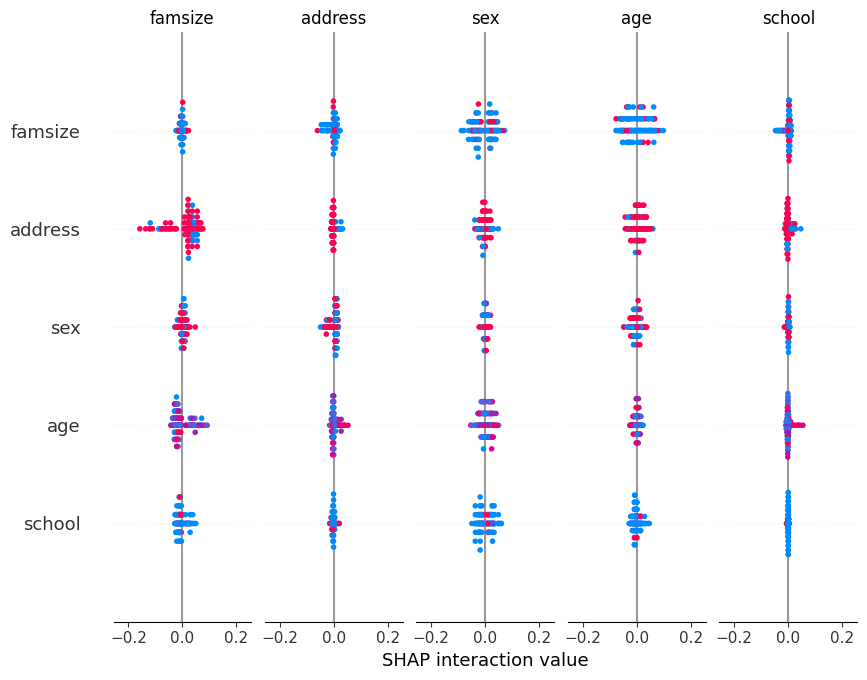

In [112]:
explicador= shap.TreeExplainer(random_forest_classifier)
shap_values = explicador.shap_values(X_test)

shap.summary_plot(shap_values, X_test, feature_names=X.columns)


Using 276 background data samples could cause slower run times. Consider using shap.sample(data, K) or shap.kmeans(data, K) to summarize the background as K samples.


  0%|          | 0/119 [00:00<?, ?it/s]

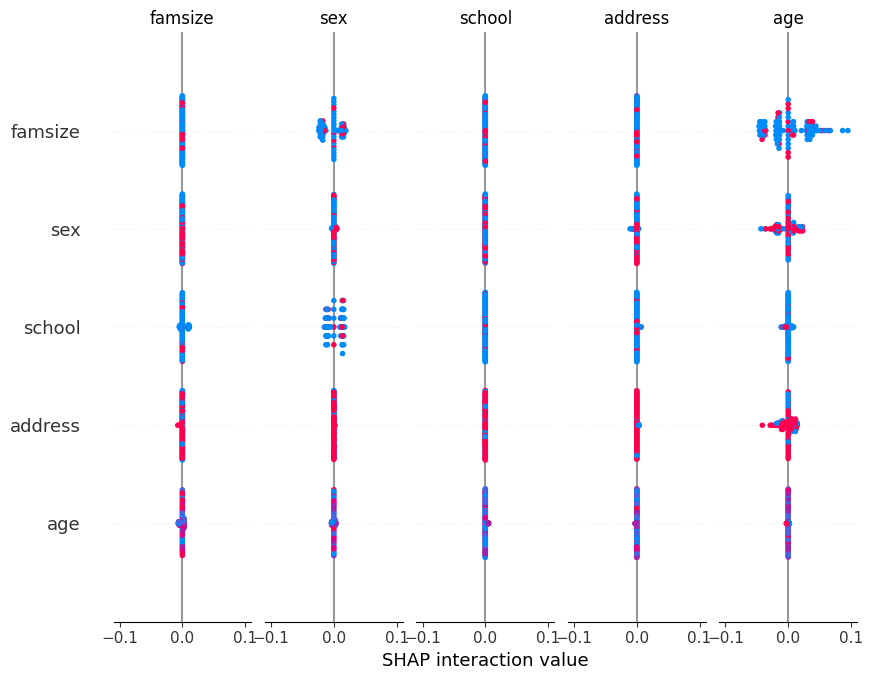

In [116]:
explicador= shap.KernelExplainer(svc.predict_proba, X_train)
shap_values = explicador.shap_values(X_test)

shap.summary_plot(shap_values, X_test, feature_names=X.columns)

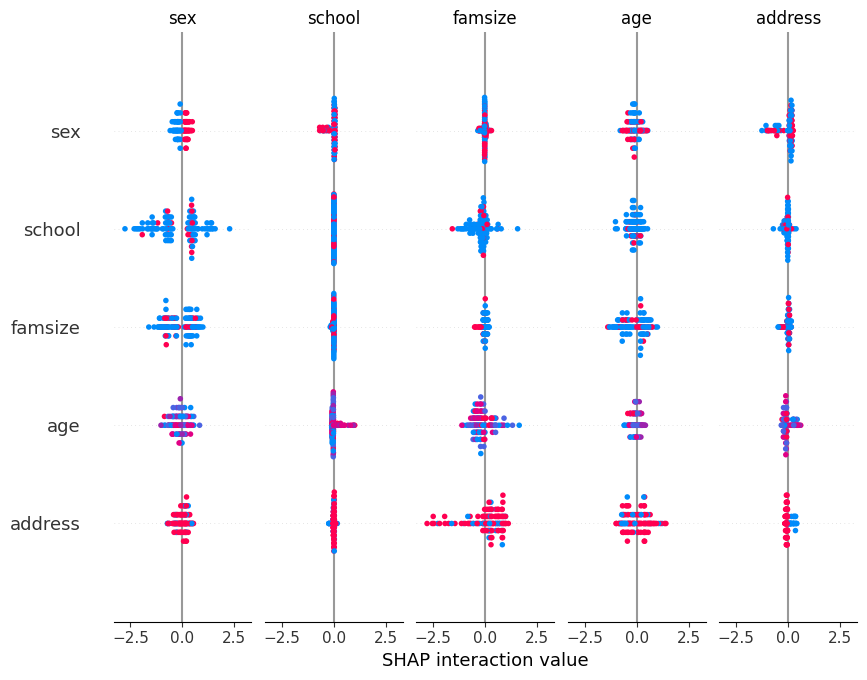

In [110]:
explicador= shap.TreeExplainer(xgb)
shap_values = explicador.shap_values(X_test)

shap.summary_plot(shap_values, X_test, feature_names=X.columns)


# 3) Aprendizado não-supervisionado - Clustering


In [135]:
clusterizacao_data = pd.read_csv('/Users/izadoraganem/7º período/TP2_IIA/Dados TP2/clustering.csv')
clusterizacao_data

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,target
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,no,no,4,3,4,1,1,3,6,F
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,yes,no,5,3,3,1,1,3,4,F
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,yes,no,4,3,2,2,3,3,10,D
3,GP,F,15,U,GT3,T,4,2,health,services,...,yes,yes,3,2,2,1,1,5,2,B
4,GP,F,16,U,GT3,T,3,3,other,other,...,no,no,4,3,2,1,2,5,4,D
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
390,MS,M,20,U,LE3,A,2,2,services,services,...,no,no,5,5,4,4,5,4,11,F
391,MS,M,17,U,LE3,T,3,1,services,services,...,yes,no,2,4,5,3,4,2,3,A
392,MS,M,21,R,GT3,T,1,1,other,other,...,no,no,5,5,3,3,3,3,3,F
393,MS,M,18,R,LE3,T,3,2,services,other,...,yes,no,4,4,1,3,4,5,0,D


In [ ]:
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score, normalized_mutual_info_score
import hdbscan
from sklearn.decomposition import PCA
import umap

y_true = clusterizacao_data['target']

encoding = LabelEncoder()
for col in clusterizacao_data.select_dtypes(include='object').columns:
    clusterizacao_data[col] = encoding.fit_transform(clusterizacao_data[col])

y_true = encoding.fit_transform(y_true)

clusterizacao_data = clusterizacao_data.drop(columns=['target'])

## 1.

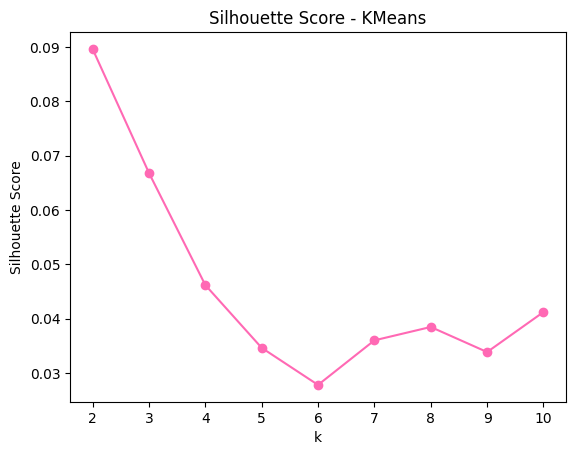

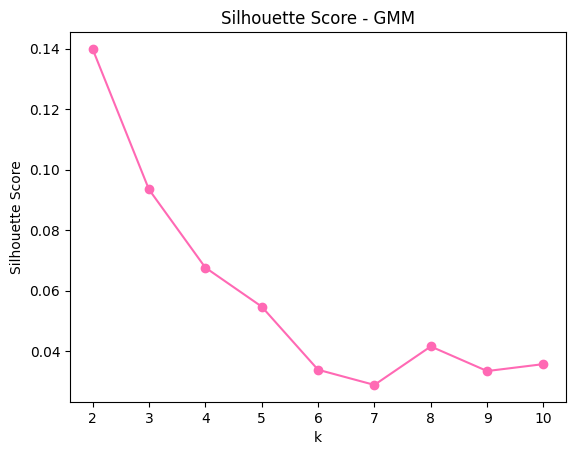

In [139]:
scaler = StandardScaler()
X = scaler.fit_transform(clusterizacao_data)

def encontrar_melhor_k(model_class, nome, X, k_range=range(2, 11)):
    scores = []
    for k in k_range:
        if nome == 'GMM':
            model = model_class(n_components=k, random_state=42)
            labels = model.fit_predict(X)
        else:
            model = model_class(n_clusters=k, random_state=42)
            labels = model.fit_predict(X)
        score = silhouette_score(X, labels)
        scores.append(score)
    plt.plot(k_range, scores, marker='o', color='hotpink')
    plt.title(f'Silhouette Score - {nome}')
    plt.xlabel('k')
    plt.ylabel('Silhouette Score')
    plt.show()
    return k_range[np.argmax(scores)]


melhor_k_kmeans = encontrar_melhor_k(KMeans, 'KMeans', X)
melhor_k_gmm = encontrar_melhor_k(GaussianMixture, 'GMM', X)


## 2.

In [ ]:
kmeans = KMeans(n_clusters = 2, random_state = 27).fit(X)

labels_kmeans = kmeans.labels_

print(f"k-means:")
print("Silhouette Score:", round(silhouette_score(X, labels_kmeans), 4))
print("Davies-Bouldin Index:", round(davies_bouldin_score(X, labels_kmeans), 4))
print("Calinski-Harabasz Index:", round(calinski_harabasz_score(X, labels_kmeans), 4))
print("Adjusted Rand Index (ARI):", round(adjusted_rand_score(y_true, labels_kmeans), 4))
print("Mutual Information Score (MI):", round(normalized_mutual_info_score(y_true, labels_kmeans), 4))

k-means:
Silhouette Score: 0.0768
Davies-Bouldin Index: 3.7219
Calinski-Harabasz Index: 25.2351
Adjusted Rand Index (ARI): 0.0005
Mutual Information Score (MI): 0.0261


In [145]:
gmm = GaussianMixture(n_components =2 , random_state = 27).fit(X)
labels_gmm = gmm.predict(X)


print(f"GMM (Gaussiam Mixture Models):")
print("Silhouette Score:", round(silhouette_score(X, labels_gmm), 4))
print("Davies-Bouldin Index:", round(davies_bouldin_score(X, labels_gmm), 4))
print("Calinski-Harabasz Index:", round(calinski_harabasz_score(X, labels_gmm), 4))
print("Adjusted Rand Index (ARI):", round(adjusted_rand_score(y_true, labels_gmm), 4))
print("Mutual Information Score (MI):", round(normalized_mutual_info_score(y_true, labels_gmm), 4))

GMM (Gaussiam Mixture Models):
Silhouette Score: 0.1651
Davies-Bouldin Index: 3.2185
Calinski-Harabasz Index: 19.7354
Adjusted Rand Index (ARI): -0.0179
Mutual Information Score (MI): 0.0389


In [146]:
hdb = hdbscan.HDBSCAN(min_cluster_size= 2).fit(X)
labels_hdb = hdb.labels_

print(f"HDBScan (Hierarchical Density-Based Spatial Clustering of Applications with Noise):")
print("Silhouette Score:", round(silhouette_score(X, labels_hdb), 4))
print("Davies-Bouldin Index:", round(davies_bouldin_score(X, labels_hdb), 4))
print("Calinski-Harabasz Index:", round(calinski_harabasz_score(X, labels_hdb), 4))
print("Adjusted Rand Index (ARI):", round(adjusted_rand_score(y_true, labels_hdb), 4))
print("Mutual Information Score (MI):", round(normalized_mutual_info_score(y_true, labels_hdb), 4))

HDBScan (Hierarchical Density-Based Spatial Clustering of Applications with Noise):
Silhouette Score: 0.1321
Davies-Bouldin Index: 3.2946
Calinski-Harabasz Index: 9.7977
Adjusted Rand Index (ARI): -0.0181
Mutual Information Score (MI): 0.0248


/opt/anaconda3/envs/py312_jupyter/lib/python3.12/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/opt/anaconda3/envs/py312_jupyter/lib/python3.12/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


In [149]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import umap
import seaborn as sns

2025-06-22 21:26:14.647493: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


### 3.

/var/folders/z6/xyw2mf3x1l96q4_w6y22mq0r0000gn/T/ipykernel_6745/2391266079.py:8: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.scatterplot(x=X_pca[:,0], y=X_pca[:,1], hue=labels_kmeans,palette=custom_palette, s=50, edgecolor='black')


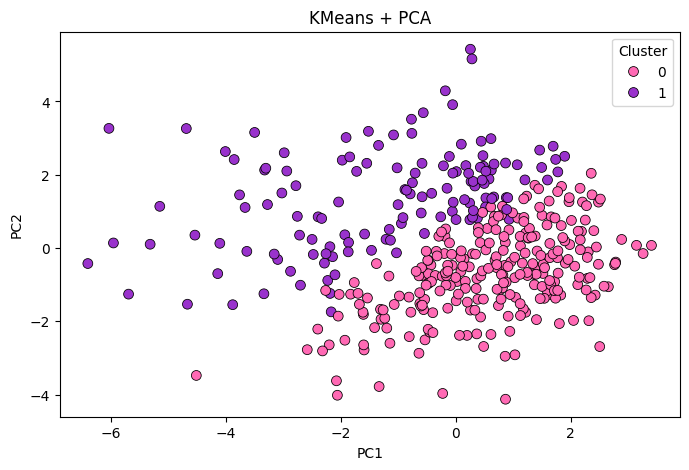

/var/folders/z6/xyw2mf3x1l96q4_w6y22mq0r0000gn/T/ipykernel_6745/2391266079.py:16: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.scatterplot(x=X_pca[:,0], y=X_pca[:,1], hue=labels_gmm,palette=custom_palette, s=50, edgecolor='black')


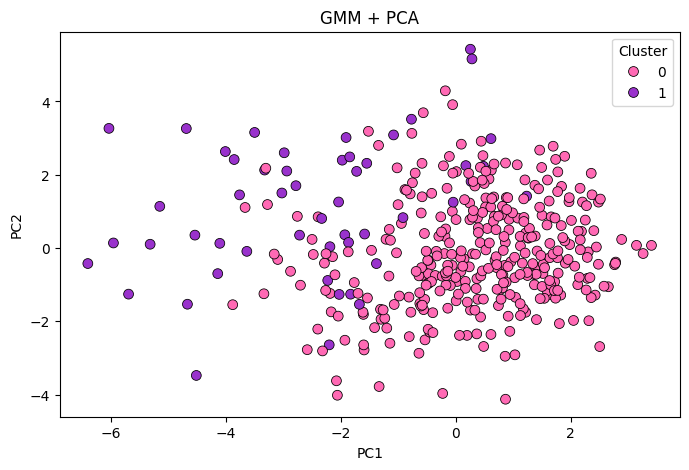

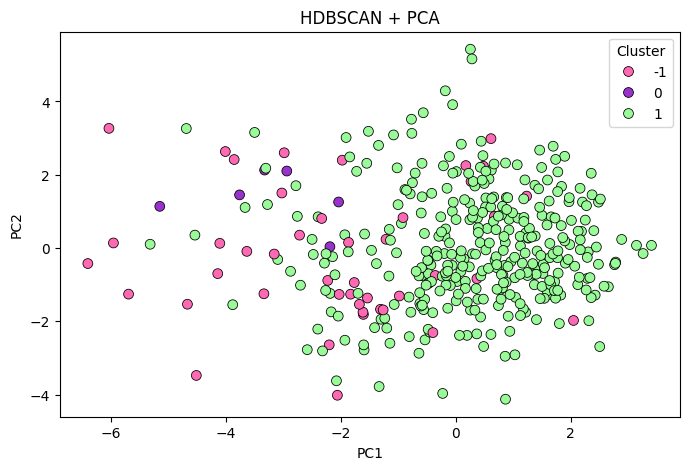

In [158]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)
variancia_pca = pca.explained_variance_ratio_.sum()

custom_palette = ['hotpink', 'darkorchid', 'palegreen']

plt.figure(figsize=(8,5))
sns.scatterplot(x=X_pca[:,0], y=X_pca[:,1], hue=labels_kmeans,palette=custom_palette, s=50, edgecolor='black')
plt.title(f'KMeans + PCA')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.legend(title="Cluster")
plt.show()

plt.figure(figsize=(8,5))
sns.scatterplot(x=X_pca[:,0], y=X_pca[:,1], hue=labels_gmm,palette=custom_palette, s=50, edgecolor='black')
plt.title('GMM + PCA')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.legend(title="Cluster")
plt.show()

plt.figure(figsize=(8,5))
sns.scatterplot(x=X_pca[:,0], y=X_pca[:,1], hue=labels_hdb,palette=custom_palette, s=50, edgecolor='black')
plt.title('HDBSCAN + PCA')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.legend(title="Cluster")
plt.show()


In [157]:
print(f"Variância explicada pelo PCA: {round(variancia_pca, 2)}")

Variância explicada pelo PCA: 0.19


/opt/anaconda3/envs/py312_jupyter/lib/python3.12/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/opt/anaconda3/envs/py312_jupyter/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/var/folders/z6/xyw2mf3x1l96q4_w6y22mq0r0000gn/T/ipykernel_6745/1239360656.py:7: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.scatterplot(x=X_umap[:,0], y=X_umap[:,1], hue=labels_kmeans, palette=custom_palette, s=50, edgecolor='black')


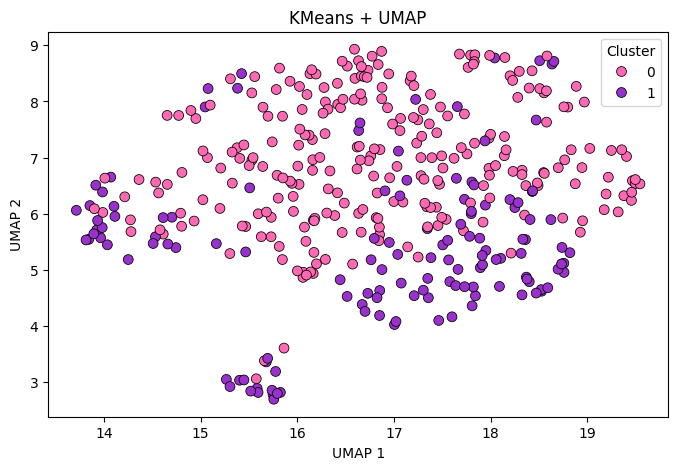

/var/folders/z6/xyw2mf3x1l96q4_w6y22mq0r0000gn/T/ipykernel_6745/1239360656.py:15: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.scatterplot(x=X_umap[:,0], y=X_umap[:,1], hue=labels_gmm, palette=custom_palette, s=50, edgecolor='black')


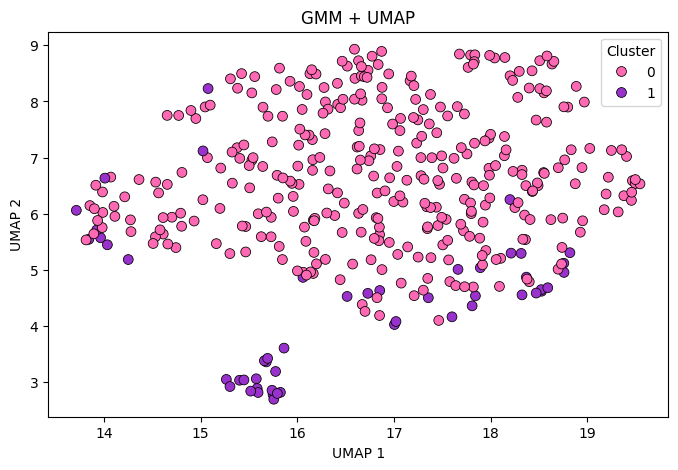

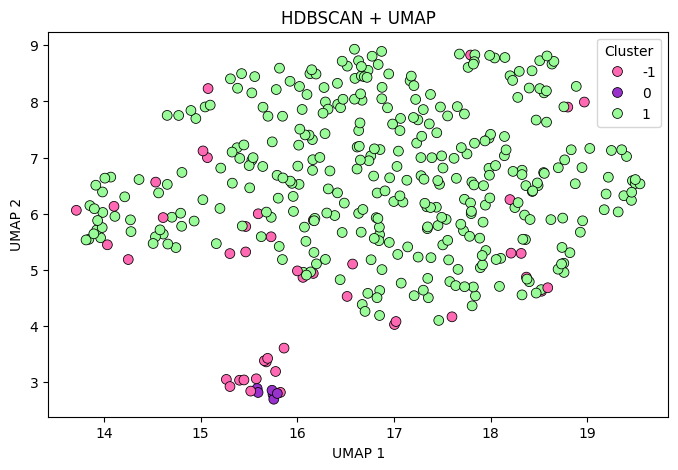

In [161]:
umap_model = umap.UMAP(random_state=42)
X_umap = umap_model.fit_transform(X)

custom_palette = ['hotpink', 'darkorchid', 'palegreen']

plt.figure(figsize=(8,5))
sns.scatterplot(x=X_umap[:,0], y=X_umap[:,1], hue=labels_kmeans, palette=custom_palette, s=50, edgecolor='black')
plt.title('KMeans + UMAP')
plt.xlabel('UMAP 1')
plt.ylabel('UMAP 2')
plt.legend(title="Cluster")
plt.show()

plt.figure(figsize=(8,5))
sns.scatterplot(x=X_umap[:,0], y=X_umap[:,1], hue=labels_gmm, palette=custom_palette, s=50, edgecolor='black')
plt.title('GMM + UMAP')
plt.xlabel('UMAP 1')
plt.ylabel('UMAP 2')
plt.legend(title="Cluster")
plt.show()

plt.figure(figsize=(8,5))
sns.scatterplot(x=X_umap[:,0], y=X_umap[:,1], hue=labels_hdb, palette=custom_palette, s=50, edgecolor='black')
plt.title('HDBSCAN + UMAP')
plt.xlabel('UMAP 1')
plt.ylabel('UMAP 2')
plt.legend(title="Cluster")
plt.show()
